# Introducción a las Redes Neuronales.

En esta libreta mostraremos el Teorema de Cybenko en acción mediante el funcionamento de una red neuronal. Esto sin el uso de librerias estándar.

## Ideas principales.
### Paso 1: Definir el problema. Estimar la función raiz cuadrada.

Por el Teorema de Cybenko sabemos que para la función $f(x)=\sqrt{x}$. Dado $\epsilon>0$, existe una red neuronal $\mathfrak{m}(\cdot,\Theta):\mathbb{R}\to\mathbb{R}$ tal que

$$
    |\mathfrak{m}(x,\Theta)-\sqrt{x}|<\epsilon
$$
Entonces construiremos una red neuronal que estime la función raiz cuadrada.

### Paso 2: Definir la red Neuronal. 
Recordando el teorema de Cybenko tenemos que 
$$
\mathfrak{m}(x,\Theta) = \sum_{n=1}^N c^n\sigma(w^nx+b^n),\Theta = \{(c^n,w^n,b^n)\}_{n=1}^N
$$
Para constuir la red neuronal debemos definir el numero de neuronas a utilizar. El Teorema de Cybenko nos dice que una capa oculta es suficiente.

### Paso 3: Función de Error.

Para entrenar la red neuronal usaremos un conjunto de datos de ejemplo $\mathcal{D}=\{(x_m,y_m)\}_{m=1}^M$ donde $M$ será la cantidad de datos. En este ejemplo usaremos la ejemplificaremos con el error cuadrático medio (MSELoss).

$$
    \ell(y,y') = (y-y')^2
$$
$$
    \Lambda(\Theta) = \dfrac{1}{M}\sum_{i=1}^{M}(y_m-\mathfrak{m}(x_m,\Theta))^{2}
$$

### Paso 4: Optimización.

El Teorema de Cybenko nos garantiza la existencia. Encontrar los parámetros, por lo general, consiste en resolver el problema de optimización.

$$
    \Theta^{*} = \argmin_{\Theta}\Lambda(\Theta)
$$

Como en este caso $\Theta\in\mathbb{R}^3$ podemos partir con el método de gradiente descendiente.

$$
    \Theta_{n+1} = \Theta_{n} - \alpha \nabla\Lambda(\Theta_n),
$$

donde $\alpha$ es la tasa de aprendizaje.


### Paso 5: Verificación.

Una vez la red haya terminado debemos verificar como actua en contraste con la función de interés. En general, se usan un conjunto de datos para entrenar y otro para verificar, en este caso podemos usar la función de interés de forma directa.


## Ejemplo. Estimar la función $f(x)=\sqrt{x}$

Para la prueba de código comenzaremos estimando la función raíz cuadrada. Esto lo haremos con una red con una neurona. Entonces iremos construyendo los elementos básicos.

### Red Neuronal $\mathfrak{m}(x,\Theta)$

In [1]:
import numpy as np

# Definimos la función de activación. El teorema nos dice que debe ser continua y de tipo sigmoidal.
def activation(x): 
    y = 1 / (1 + np.exp(-x))
    return y

# Construimos la red neuronal. 
def model(x, theta, func=activation):
    # Se ve sencilla porque es una neurona.
    c = theta[0]
    w = theta[1]
    b = theta[2]
    v = w * x + b
    y = c * func(v)
    return y

### Función de Error $\Lambda(\Theta)$

In [2]:
# La función de error. El error cuadrático medio.
def MSE_nn(yv, xv, m, pars):
    M = len(yv)
    assert M == len(xv), "Revisa dimensiones"
    pred = np.array([m(x, pars) for x in xv])
    ell = (yv-pred) ** 2
    Lambda = M ** (-1) * ell.sum()
    return Lambda


### Optimización. Descenso Gradiente $\alpha$.

Para construirlo desde cero debemos recordar 2 elementos importantes. Sea $f:\mathbb{R}^d\to \mathbb{R}$ con $h$ suficientemente pequeña
$$
    \partial_{i}f=\dfrac{\partial f}{\partial x_i} \approx \dfrac{1}{h}(f(v+he_i)-f(v)),i=1,\ldots,d,
$$

$$
    \nabla f = (\partial_1f,\ldots,\partial_d f).
$$

Y la función a la que debemos sacar el gradiente 
$$
    \Lambda(\Theta) = \dfrac{1}{M}\sum_{i=1}^{M}(y_m-c\sigma(wx_m+b))^{2}
$$

In [3]:
import numpy as np


train_y = np.arange(0, 10)
train_x = train_y ** 2

# Funcion auxiliar para el algoritmo de gradiente descendente. 
## Requiere los datos de entrenamiento previamente definidos.
def error_learn(theta):
    y = MSE_nn(yv = train_y, xv = train_x, m=model, pars=theta)
    return y


def partial(func, rspct, v, tol=10**(-5)):
    d = len(v)
    assert 0 < rspct <= d, "Revisa la variable a derivar"
    e_i = np.array([1 if i==rspct else 0 for i in range(1, d+1)])
    df = func(v + e_i * tol) - func(v)
    pr = tol ** (-1) * df
    return pr


def gradient(func, v):
    d = len(v)
    # Usaremos la tolerancia definida en la derivada parcial.
    gd = np.array([partial(func, i + 1, v) for i in range(d)])
    return gd

**NOTA** Dejamos las derivadas parciales de la función de error por si quiere verificar los valores del gradiente.


\begin{align*}
\partial_{c}\Lambda & =\dfrac{2}{M}\sum^{M}_{i=1}\left(y_{m}-c\sigma(wx_{m}+b)\right)\left(-\sigma\left(wx_{m}+b\right)\right)\\
\partial_{w}\Lambda & =\dfrac{2}{M}\sum^{M}_{i=1}\left(y_{m}-c\sigma(wx_{m}+b)\right)\left(-c\partial_{w}\sigma\right),\\
\partial_{w}\Lambda & =\dfrac{2}{M}\sum^{M}_{i=1}\left(y_{m}-c\sigma(wx_{m}+b)\right)\left(-c\partial_{b}\sigma\right).
\end{align*}

Usando la sigmoide 
\begin{align*}
\sigma\left(wx_{m}+b\right) & =\dfrac{1}{1+\exp\left(-wx_{m}-b\right)}=\left(1+\exp\left(-wx_{m}-b\right)\right)^{-1}\\
\partial_{w}\sigma & =-\left(1+\exp\left(-wx_{m}-b\right)\right)^{-2}\left(-x_{m}\exp\left(-wx_{m}-b\right)\right)\\
\partial_{b}\sigma & =-\left(1+\exp\left(-wx_{m}-b\right)\right)^{-2}\left(-\exp\left(-wx_{m}-b\right)\right)
\end{align*}



In [4]:
def descent_gradent(func, theta0, epsilon, stop = 100, lr = 0.01):
    error = func(theta0)
    epochs = 0
    while error > epsilon:
        thetan = theta0 - lr * gradient(error_learn, theta0)
        error = func(thetan)
        t_n1 = np.array(thetan)
        t_n = np.array(theta0)
        diff = (t_n1 - t_n) ** 2
        near = np.sqrt(diff.sum())
        if near < epsilon:
            break
        theta0 = thetan
        if epochs % 1000 == 0:
            print(epochs, near)
        epochs+=1
    print("Error", error)
    return theta0


param_fit = descent_gradent(error_learn, [0.1,0.1,0.1], 0.01)
param_fit

0 0.08247561981341264
Error 0.7844840398768326


array([ 6.90024336,  0.12723856, -1.83136053])

### Verificación

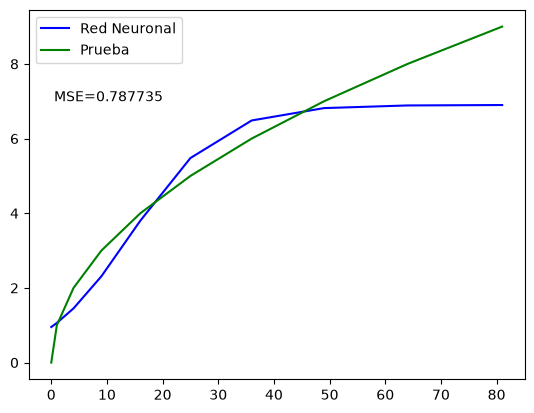

In [5]:
import matplotlib.pyplot as plt

def fitmodel(v):
    return model(v, param_fit)

predicted = [fitmodel(x) for x in train_x]
fig, ax = plt.subplots()
ax.plot(train_x, predicted, color="blue", label="Red Neuronal")
ax.plot(train_x, train_y, color="green", label="Prueba")
ax.annotate(text=f"MSE={error_learn(param_fit):2f}", xy=[0.5,7])
ax.legend()

## ¿Que pasó?

El error de los datos de prueba con la red neuronal es muy grande. Esto es normal y no tiene nada que ver con el Teorema de Cybenko. Recordemos que usamos la función de activación sigmoide
$$
    S(x)=\dfrac{1}{1+e^{-x}}.
$$

Se puede verificar que 
$$
    0\leq S(x)\leq 1,\forall x\in\mathbb{R}.
$$

Entonces es esperable, recordando que $\sqrt{x}$ no esta acotada, que fallará al aproximar.

